# AI vs human QA raters: how well do they agree?

An AI scorer drafts a 100-point QA score for each support conversation (18 criteria across 6 sections); a human reviewer's score is the reference. This notebook measures **agreement**, not just accuracy: where the AI matches the human, where it is systematically harsh or lenient, and whether its stated confidence means anything.

> **Data caveat.** Everything here is **synthetic**. The conversations are generated by a seeded script and the "human" scores are simulated reviewers. The AI side is the repo's **mock scorer**, a keyword and timing heuristic, not a language model. The numbers demonstrate the *method* and act as a regression guard for the pipeline; they are not a claim about any real model or team.

Sections: 1 overall agreement, 2 pass/fail agreement, 3 per-criterion agreement and bias, 4 confidence calibration, 5 recommendations.

In [1]:
import textwrap
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import cohen_kappa_score, confusion_matrix
from statsmodels.stats.weightstats import DescrStatsW
from scipy.stats import spearmanr

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
BLUE, ORANGE, GREY = "#2a6fdb", "#d9822b", "#6b7280"
PASS_MARK, TOLERANCE, N_BOOT = 90, 5, 5000
rng = np.random.default_rng(42)

DATA = Path("data")
full, sample = DATA / "eval_criteria.csv", DATA / "sample_eval.csv"
src = full if full.exists() else sample
df = pd.read_csv(src)
DOCS = Path("../docs"); DOCS.mkdir(exist_ok=True)
conv = df.drop_duplicates("conversation_id").set_index("conversation_id")
print(f"source: {src.as_posix()}  ->  {len(conv)} conversations x {df.criterion_id.nunique()} criteria = {len(df)} rows")
if src == sample:
    print("NOTE: using the small committed sample; run `npm run eval:export` for the full golden set.")
df.head(6)

source: data/eval_criteria.csv  ->  20 conversations x 18 criteria = 360 rows


,conversation_id,agent,date,criterion_id,criterion_label,section,max_points,ai_points,human_points,deterministic,ai_total,human_total,ai_pass,human_pass,ai_confidence
0,CONV-0001,Agent Alpha,2025-03-03,g1,Introduces self and addresses the customer,greeting,5,5,5,0,100,94,1,1,0.95
1,CONV-0001,Agent Alpha,2025-03-03,g2,First reply within target time,greeting,10,10,10,1,100,94,1,1,0.95
2,CONV-0001,Agent Alpha,2025-03-03,g3,No long gaps between messages,greeting,5,5,5,0,100,94,1,1,0.95
3,CONV-0001,Agent Alpha,2025-03-03,u1,Asks the right questions,understanding,5,5,3,0,100,94,1,1,0.95
4,CONV-0001,Agent Alpha,2025-03-03,u2,Validates customer information,understanding,5,5,5,0,100,94,1,1,0.95
5,CONV-0001,Agent Alpha,2025-03-03,u3,Shows empathy,understanding,5,5,5,0,100,94,1,1,0.95


## 1. Overall agreement on the total score

Three views of the same question: how often is the AI within +/-5 points of the human, how large is the typical miss (mean absolute error), and, with a Bland-Altman analysis, is there a *systematic* offset (bias) and how wide is the range in which most disagreements fall (limits of agreement, bias +/- 1.96 SD)?

In [2]:
ai, hu = conv.ai_total.to_numpy(float), conv.human_total.to_numpy(float)
diff = ai - hu                      # positive = AI more lenient than the human
mean_pair = (ai + hu) / 2

within = float(np.mean(np.abs(diff) <= TOLERANCE))
mae = float(np.mean(np.abs(diff)))
bias, sd = float(diff.mean()), float(diff.std(ddof=1))
loa_lo, loa_hi = bias - 1.96 * sd, bias + 1.96 * sd
bias_ci = DescrStatsW(diff).tconfint_mean()

overall = pd.Series({
    "conversations": len(diff),
    f"within +/-{TOLERANCE} pts": f"{within:.1%} ({int(np.sum(np.abs(diff) <= TOLERANCE))}/{len(diff)})",
    "mean absolute error (pts)": round(mae, 2),
    "bias, AI - human (pts)": round(bias, 2),
    "bias 95% CI (t)": f"[{bias_ci[0]:.2f}, {bias_ci[1]:.2f}]",
    "SD of differences": round(sd, 2),
    "limits of agreement (pts)": f"[{loa_lo:.2f}, {loa_hi:.2f}]",
})
overall

conversations                           20
within +/-5 pts              80.0% (16/20)
mean absolute error (pts)             3.15
bias, AI - human (pts)                2.85
bias 95% CI (t)               [1.64, 4.06]
SD of differences                     2.58
limits of agreement (pts)    [-2.21, 7.91]
dtype: object

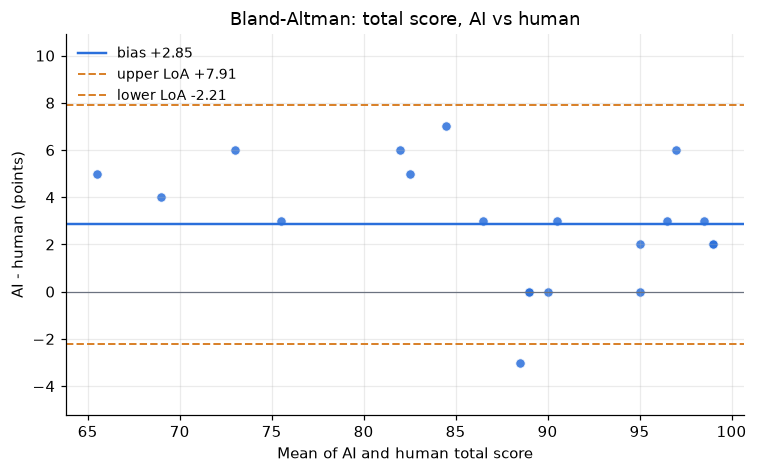

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.4))
ax.scatter(mean_pair, diff, s=38, color=BLUE, alpha=0.85, edgecolor="white", linewidth=0.6)
ax.axhline(bias, color=BLUE, lw=1.6, label=f"bias {bias:+.2f}")
for y, lab in [(loa_hi, f"upper LoA {loa_hi:+.2f}"), (loa_lo, f"lower LoA {loa_lo:+.2f}")]:
    ax.axhline(y, color=ORANGE, lw=1.3, ls="--", label=lab)
ax.axhline(0, color=GREY, lw=0.8)
ax.set_xlabel("Mean of AI and human total score")
ax.set_ylabel("AI - human (points)")
ax.set_title("Bland-Altman: total score, AI vs human")
ax.set_ylim(loa_lo - 3, loa_hi + 3)
ax.legend(loc="upper left", frameon=False, fontsize=9)
fig.tight_layout(); fig.savefig(DOCS / "bland_altman.png", dpi=150); plt.show()

**Reading it.** A positive bias means the AI is more lenient than the human on average. The dashed lines are the 95% limits of agreement: a new AI-vs-human gap is expected to land between them about 19 times in 20 *if* the differences are roughly normal. With only a few dozen conversations the limits themselves are uncertain, so treat them as a rough guide.

## 2. Pass/fail agreement

The business decision is pass (total >= 90) or fail. Cohen's kappa corrects raw agreement for the agreement expected by chance; a percentile bootstrap over conversations (5,000 resamples) gives a 95% confidence interval.

In [4]:
ai_p, hu_p = conv.ai_pass.to_numpy(int), conv.human_pass.to_numpy(int)
cm = confusion_matrix(hu_p, ai_p, labels=[0, 1])
cm_df = pd.DataFrame(cm, index=["human fail", "human pass"], columns=["AI fail", "AI pass"])
raw_agree = float(np.mean(ai_p == hu_p))
kappa = cohen_kappa_score(hu_p, ai_p)

boots = []
n = len(ai_p)
for _ in range(N_BOOT):
    idx = rng.integers(0, n, n)
    a, h = ai_p[idx], hu_p[idx]
    if len(set(a) | set(h)) < 2:      # kappa undefined when both raters are constant
        continue
    k = cohen_kappa_score(h, a)
    if not np.isnan(k):
        boots.append(k)
k_lo, k_hi = np.percentile(boots, [2.5, 97.5])
print(f"raw pass/fail agreement: {raw_agree:.1%}")
print(f"Cohen's kappa: {kappa:.3f}   bootstrap 95% CI [{k_lo:.3f}, {k_hi:.3f}]   (valid resamples: {len(boots)}/{N_BOOT})")
cm_df

raw pass/fail agreement: 90.0%
Cohen's kappa: 0.798   bootstrap 95% CI [0.479, 1.000]   (valid resamples: 5000/5000)


,AI fail,AI pass
human fail,10,1
human pass,1,8


Rule of thumb (Landis & Koch): 0.61-0.80 substantial, above 0.80 almost perfect. Quote the interval rather than the point estimate: it is wide because the golden set is small and the disagreements are concentrated near the pass mark.

In [5]:
mis = conv.assign(diff=diff)[conv.ai_pass != conv.human_pass][["ai_total", "human_total", "diff"]]
print(f"{len(mis)} pass/fail disagreement(s):" if len(mis) else "no pass/fail disagreements")
mis

2 pass/fail disagreement(s):


,ai_total,human_total,diff
conversation_id,,,
CONV-0014,87,90,-3.0
CONV-0039,92,89,3.0


## 3. Per-criterion agreement and bias

For each of the 18 criteria: **quadratic-weighted kappa** (agreement on the 0..max-points scale, penalising large misses more than near-misses), the **exact-match rate**, and the **systematic bias** (mean AI points minus mean human points). Bias is also shown as a share of the criterion's maximum so criteria worth different points can be compared. `g2` (first reply within target) is computed deterministically from timestamps on both sides, so it is excluded from the ranking.

A weighted kappa is undefined (NaN) when one rater gives the same score every time on a criterion; that is shown as `n/a`, not as zero.

In [6]:
def wkappa(h, a, mx):
    if len(set(h)) < 2 or len(set(a)) < 2:
        return np.nan
    return cohen_kappa_score(h, a, weights="quadratic", labels=list(range(mx + 1)))

rows = []
for cid, g in df.groupby("criterion_id", sort=False):
    mx = int(g.max_points.iloc[0])
    h, a = g.human_points.to_numpy(int), g.ai_points.to_numpy(int)
    d = a - h
    bs = [rng.choice(d, len(d)).mean() for _ in range(2000)]
    rows.append({
        "criterion": cid, "label": g.criterion_label.iloc[0], "section": g.section.iloc[0], "max_pts": mx,
        "deterministic": bool(g.deterministic.iloc[0]),
        "bias_pts": d.mean(), "bias_pct_of_max": 100 * d.mean() / mx,
        "bias_lo": np.percentile(bs, 2.5), "bias_hi": np.percentile(bs, 97.5),
        "mean_abs_err": np.abs(d).mean(), "exact_match": float(np.mean(d == 0)),
        "weighted_kappa": wkappa(h, a, mx),
    })
crit = pd.DataFrame(rows)
rank = crit[~crit.deterministic].sort_values("bias_pct_of_max", ascending=False).reset_index(drop=True)
rank.index += 1
show = rank[["criterion", "label", "max_pts", "bias_pts", "bias_pct_of_max", "mean_abs_err", "exact_match", "weighted_kappa"]].copy()
show["weighted_kappa"] = show.weighted_kappa.map(lambda v: "n/a" if pd.isna(v) else f"{v:.2f}")
show.round({"bias_pts": 2, "bias_pct_of_max": 1, "mean_abs_err": 2, "exact_match": 2}).rename_axis("rank")

,criterion,label,max_pts,bias_pts,bias_pct_of_max,mean_abs_err,exact_match,weighted_kappa
rank,,,,,,,,
1,p2,Documents actions and exceptions,7,1.05,15.0,1.05,0.65,0.57
2,u3,Shows empathy,5,0.40,8.0,0.40,0.80,0.84
3,u1,Asks the right questions,5,0.35,7.0,0.35,0.85,0.85
4,g1,Introduces self and addresses the customer,5,0.25,5.0,0.25,0.90,0.89
5,t2,Shows appreciation,2,0.10,5.0,0.10,0.90,0.81
6,c2,Confirms all needs are met,5,0.20,4.0,0.20,0.90,0.85
7,t3,Closing courtesy phrase,2,0.05,2.5,0.05,0.95,0.94
8,r2,Proposes a correct solution,10,0.25,2.5,0.25,0.95,0.77
9,r1,Takes the right system action,6,0.15,2.5,0.45,0.85,0.81


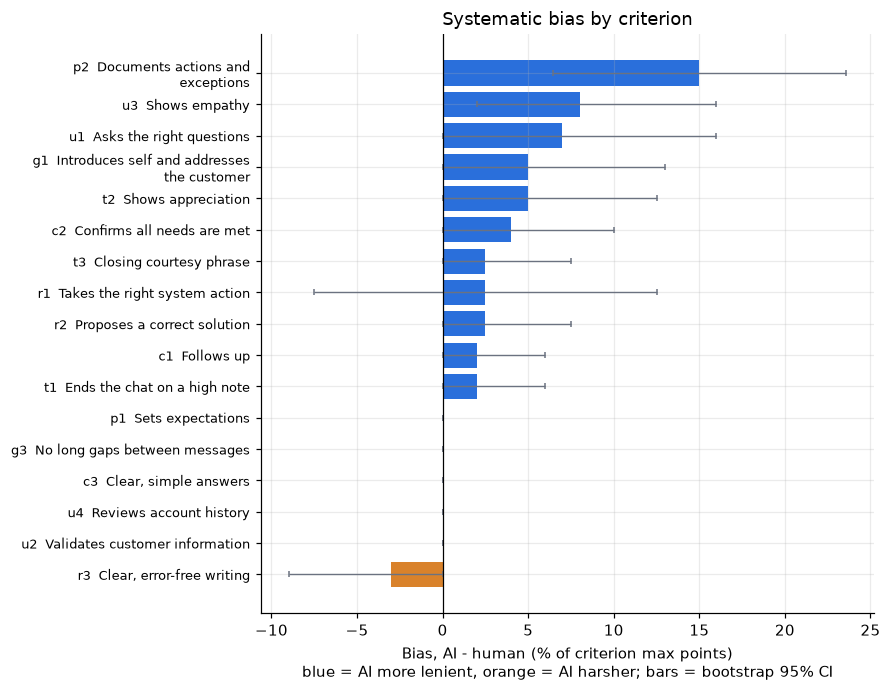

In [7]:
plot = rank.sort_values("bias_pct_of_max")
colors = [BLUE if v > 0 else ORANGE for v in plot.bias_pct_of_max]
fig, ax = plt.subplots(figsize=(8.2, 6.4))
y = np.arange(len(plot))
lo = plot.bias_pct_of_max - 100 * plot.bias_lo / plot.max_pts
hi = 100 * plot.bias_hi / plot.max_pts - plot.bias_pct_of_max
ax.barh(y, plot.bias_pct_of_max, color=colors, xerr=[lo, hi], error_kw={"ecolor": GREY, "lw": 0.9, "capsize": 2})
ax.set_yticks(y, [f"{c}  " + textwrap.fill(l, 30, subsequent_indent="      ") for c, l in zip(plot.criterion, plot.label)], fontsize=8.5)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Bias, AI - human (% of criterion max points)\nblue = AI more lenient, orange = AI harsher; bars = bootstrap 95% CI")
ax.set_title("Systematic bias by criterion")
fig.tight_layout(); fig.savefig(DOCS / "criterion_bias.png", dpi=150); plt.show()

In [8]:
lenient = rank[rank.bias_pct_of_max > 0].head(3)[["criterion", "label", "bias_pts", "bias_pct_of_max"]]
harsh = rank[rank.bias_pct_of_max < 0].sort_values("bias_pct_of_max").head(3)[["criterion", "label", "bias_pts", "bias_pct_of_max"]]
print("Most LENIENT criteria (AI gives more than the human):"); print(lenient.round(2).to_string(index=False))
print()
print("Most HARSH criteria (AI gives less than the human):" if len(harsh) else "No criterion where the AI is harsher on average.")
if len(harsh): print(harsh.round(2).to_string(index=False))

Most LENIENT criteria (AI gives more than the human):
criterion                            label  bias_pts  bias_pct_of_max
       p2 Documents actions and exceptions      1.05             15.0
       u3                    Shows empathy      0.40              8.0
       u1         Asks the right questions      0.35              7.0

Most HARSH criteria (AI gives less than the human):
criterion                     label  bias_pts  bias_pct_of_max
       r3 Clear, error-free writing     -0.15             -3.0


## 4. Does the AI's confidence mean anything?

Each draft carries a self-reported confidence. If it is calibrated, higher confidence should go with a higher chance of agreeing with the human. Conversations are split into equal-sized confidence bins (the golden set is small, so three bins) and "agreement" means the AI total is within +/-5 points of the human total. Also reported: the Spearman correlation between confidence and absolute error (negative = confidence is informative).

Spearman(confidence, |error|) = 0.01  (p = 0.983, n = 20)


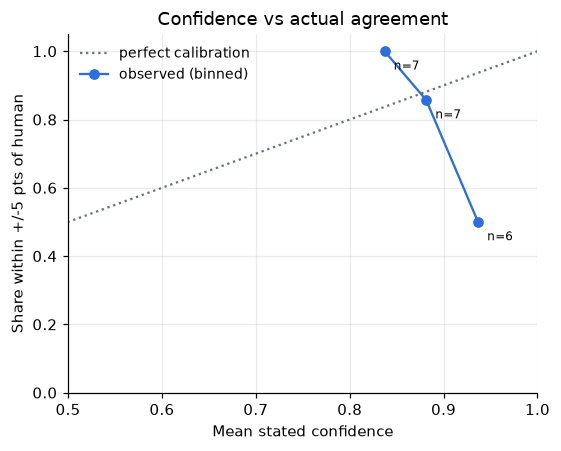

In [9]:
has_conf = bool(conv.ai_confidence.notna().all()) and conv.ai_confidence.nunique() > 3
rho = np.nan
if not has_conf:
    print("No usable AI confidence in this export (missing or near-constant). Calibration skipped.")
else:
    c = conv.assign(abs_err=np.abs(diff), agree=(np.abs(diff) <= TOLERANCE).astype(int))
    c["bin"] = pd.qcut(c.ai_confidence, q=3, duplicates="drop")
    cal = c.groupby("bin", observed=True).agg(n=("agree", "size"), mean_conf=("ai_confidence", "mean"),
                                              agreement=("agree", "mean"), mean_abs_err=("abs_err", "mean")).reset_index(drop=True)
    rho, p = spearmanr(c.ai_confidence, c.abs_err)
    print(f"Spearman(confidence, |error|) = {rho:.2f}  (p = {p:.3f}, n = {len(c)})")
    fig, ax = plt.subplots(figsize=(5.2, 4.2))
    ax.plot([0, 1], [0, 1], color=GREY, ls=":", label="perfect calibration")
    ax.plot(cal.mean_conf, cal.agreement, "o-", color=BLUE, label="observed (binned)")
    for _, r in cal.iterrows():
        ax.annotate(f"n={int(r.n)}", (r.mean_conf, r.agreement), textcoords="offset points", xytext=(6, -12), fontsize=8)
    ax.set_xlim(0.5, 1.0); ax.set_ylim(0, 1.05)
    ax.set_xlabel("Mean stated confidence"); ax.set_ylabel(f"Share within +/-{TOLERANCE} pts of human")
    ax.set_title("Confidence vs actual agreement"); ax.legend(frameon=False, fontsize=9)
    fig.tight_layout(); fig.savefig(DOCS / "confidence_calibration.png", dpi=150); plt.show()
    cal.round(3)

**Reading it.** The mock scorer derives its confidence from how many criteria earned only partial credit plus a small deterministic jitter, so it is a crude signal. The table shows whether a reviewer could use it to prioritise. With few conversations per bin, differences between bins are suggestive only.

## 5. What a QA lead should do

The three recommendations below are generated from the numbers above (the text is computed, so it cannot drift from the results).

In [10]:
top_len = rank.iloc[0]
weak = rank[rank.criterion != top_len.criterion].sort_values(["exact_match", "mean_abs_err"], ascending=[True, False]).iloc[0]
n_dis = int((conv.ai_pass != conv.human_pass).sum())
band = conv[(conv.ai_total >= PASS_MARK - TOLERANCE) & (conv.ai_total < PASS_MARK + TOLERANCE)]
n_dis_band = int(((conv.ai_pass != conv.human_pass) & conv.index.isin(band.index)).sum())
recs = [
    f"1. Calibrate the AI on '{top_len.criterion}' ({top_len.label}) before trusting its totals. It is the most lenient criterion "
    f"at {top_len.bias_pts:+.2f} pts per conversation on average ({top_len.bias_pct_of_max:+.0f}% of its maximum), and the overall total "
    f"drifts the same way (bias {bias:+.2f} pts, limits of agreement [{loa_lo:.1f}, {loa_hi:.1f}]). Its weighted kappa is {top_len.weighted_kappa:.2f} and only {top_len.exact_match:.0%} of scores match exactly, so feed reviewer corrections on this criterion back as learning signals.",
    f"2. Tighten the rubric wording (or keep a human on) '{weak.criterion}' ({weak.label}): after the criterion above it has the lowest exact-match rate "
    f"({weak.exact_match:.0%}), a mean absolute error of {weak.mean_abs_err:.2f} pts and a bias of {weak.bias_pts:+.2f} pts "
    f"(weighted kappa {weak.weighted_kappa:.2f}). Subjective criteria with no observable anchor are where a heuristic and a person drift apart; "
    f"in contrast {int((rank.exact_match == 1).sum())} criteria agree on every conversation and need no extra review.",
    f"3. Always send drafts within +/-{TOLERANCE} points of the {PASS_MARK}-point pass mark to human review: pass/fail kappa is {kappa:.2f} "
    f"(95% CI {k_lo:.2f} to {k_hi:.2f}), and {n_dis_band} of the {n_dis} pass/fail disagreements sit in that band "
    f"({len(band)} of {len(conv)} conversations fall in it). Far from the mark a {TOLERANCE}-point error cannot flip the verdict, so trust the AI more there."
    + (f" Confidence is only a {'weak' if abs(rho) < 0.4 else 'moderate-to-strong'} triage signal here (Spearman with |error| = {rho:.2f}), so do not use it alone to skip review." if has_conf else ""),
]
for r in recs: print(r, end="\n\n")

1. Calibrate the AI on 'p2' (Documents actions and exceptions) before trusting its totals. It is the most lenient criterion at +1.05 pts per conversation on average (+15% of its maximum), and the overall total drifts the same way (bias +2.85 pts, limits of agreement [-2.2, 7.9]). Its weighted kappa is 0.57 and only 65% of scores match exactly, so feed reviewer corrections on this criterion back as learning signals.

2. Tighten the rubric wording (or keep a human on) 'u3' (Shows empathy): after the criterion above it has the lowest exact-match rate (80%), a mean absolute error of 0.40 pts and a bias of +0.40 pts (weighted kappa 0.84). Subjective criteria with no observable anchor are where a heuristic and a person drift apart; in contrast 5 criteria agree on every conversation and need no extra review.

3. Always send drafts within +/-5 points of the 90-point pass mark to human review: pass/fail kappa is 0.80 (95% CI 0.48 to 1.00), and 2 of the 2 pass/fail disagreements sit in that band

### Limits of this analysis

- **Synthetic data, heuristic scorer.** The simulated reviewers and the mock scorer are both artificial; real raters also disagree with each other, which this setup does not model (no inter-human baseline).
- **Small n.** One golden set of 20 conversations (360 criterion-level pairs, which are *not* independent within a conversation). Intervals are wide; all conclusions are directional.
- **One reference rater.** Kappa treats the human score as ground truth. With real data, compare the AI against human-vs-human agreement as the ceiling.
- **Reproducibility.** The export is deterministic (seeded data, deterministic mock scorer) and bootstrap resampling uses a fixed seed, so re-running gives identical numbers.